In [1]:



import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline as Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, roc_auc_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
import warnings
warnings.filterwarnings("ignore")


In [2]:

import kagglehub

path = kagglehub.dataset_download("sztuanakurun/diabates")
df=pd.read_csv('/kaggle/input/datasets/sztuanakurun/diabates/diabetes.csv')

print("Columns: \n")
df.columns

Columns: 



Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

In [3]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:

print("Duplicate rows:", df.duplicated().sum())
display(df.isnull().sum().to_frame("missing_values"))
display(df.describe(include="all").T)


Duplicate rows: 0


,missing_values
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


## 2. Univariate EDA

The target outcome count plot is shown first, followed by distributions for all predictor columns. Numeric distributions use KDE when it is meaningful and possible.


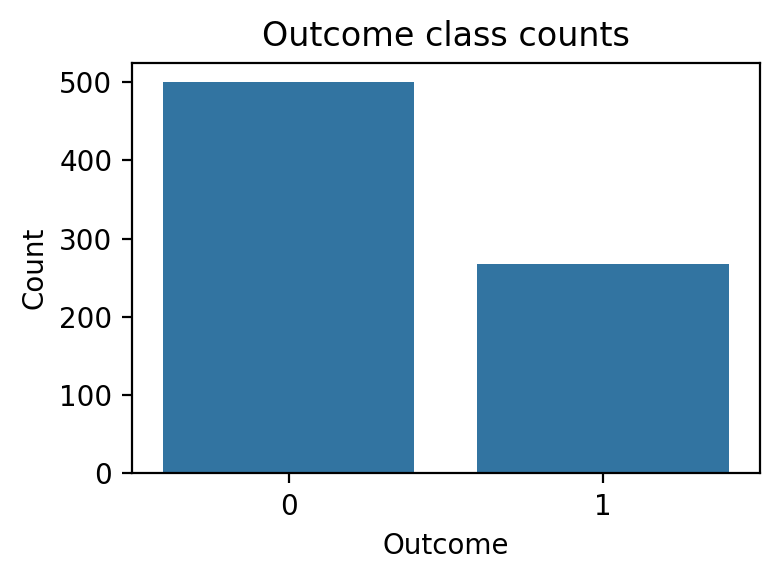

In [5]:
TARGET = "Outcome"

plt.figure(figsize=(4, 3), dpi=200)
ax = sns.countplot(data=df, x=TARGET)
ax.set_title("Outcome class counts")
ax.set_xlabel("Outcome")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

In [6]:

invalid_zero_cols = [
    c for c in ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
    if c in df.columns
]
df[invalid_zero_cols] = df[invalid_zero_cols].replace(0, np.nan)

print("Missing values after converting invalid zeros:")
display(df[invalid_zero_cols].isna().sum().to_frame("missing_values"))

# Outlier capping is done AFTER the train/test split (section 5),
# so the caps are learned from the training data only.


Missing values after converting invalid zeros:


,missing_values
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11


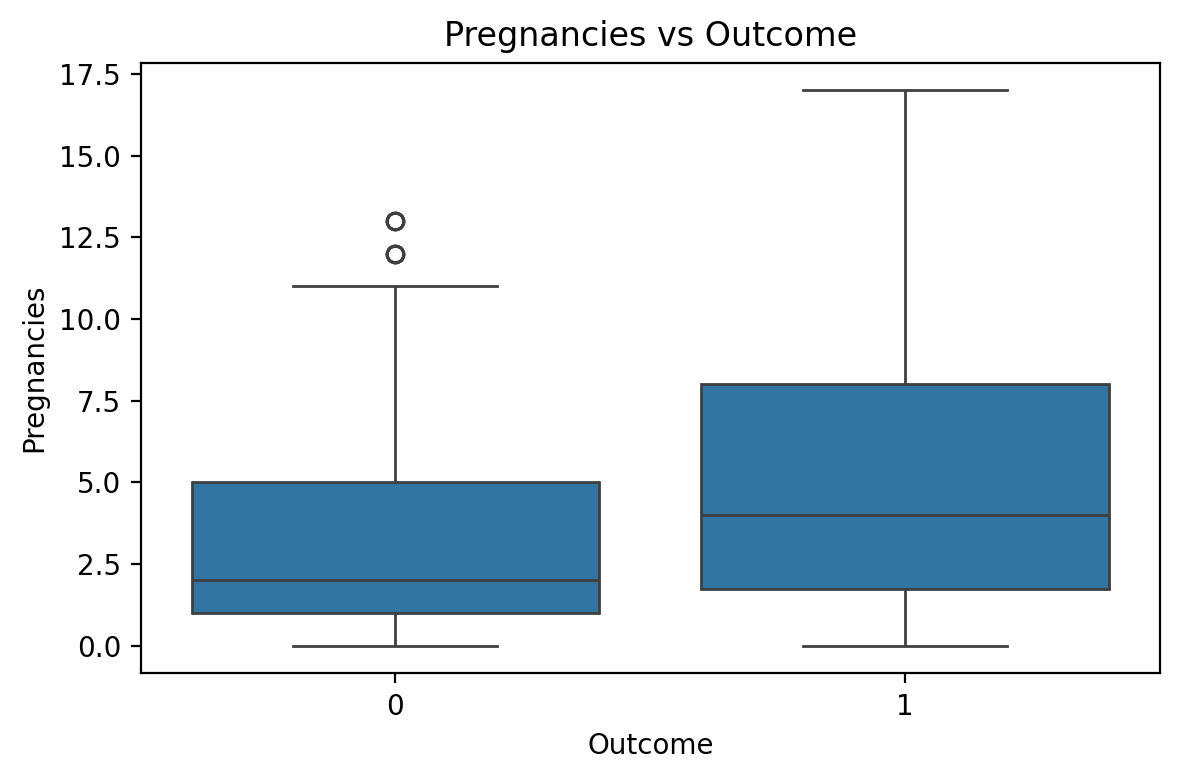

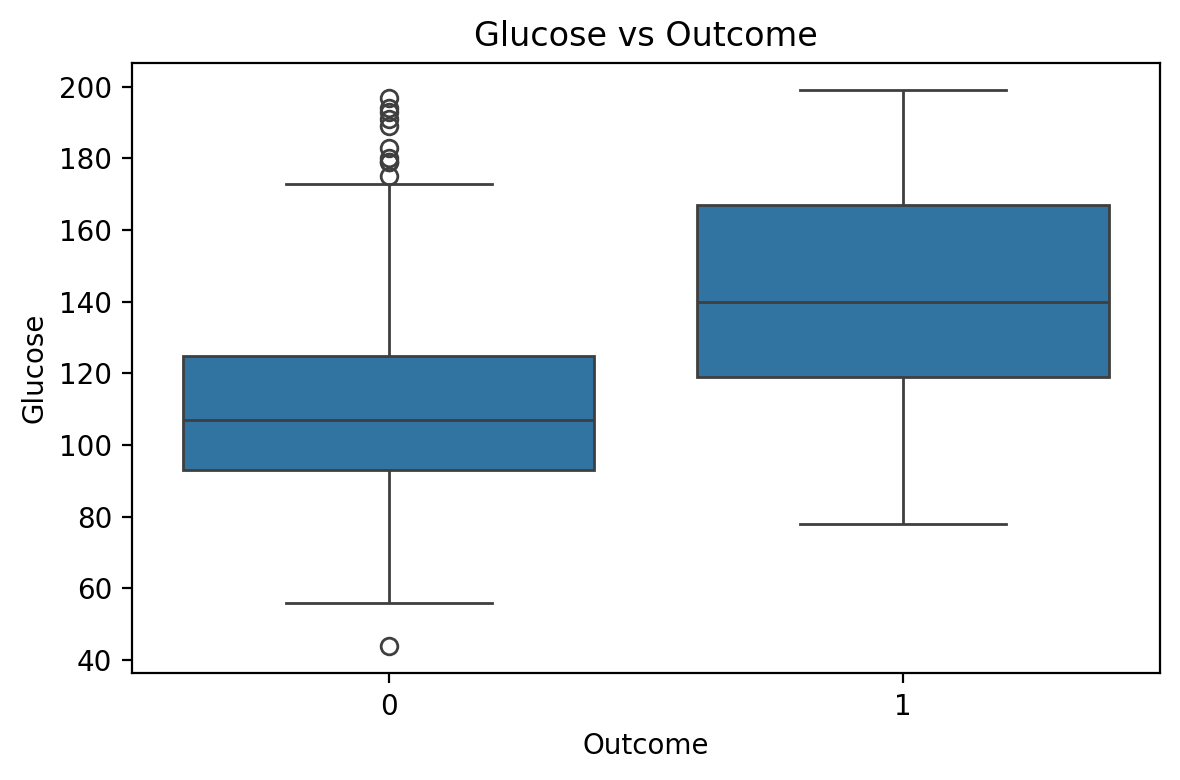

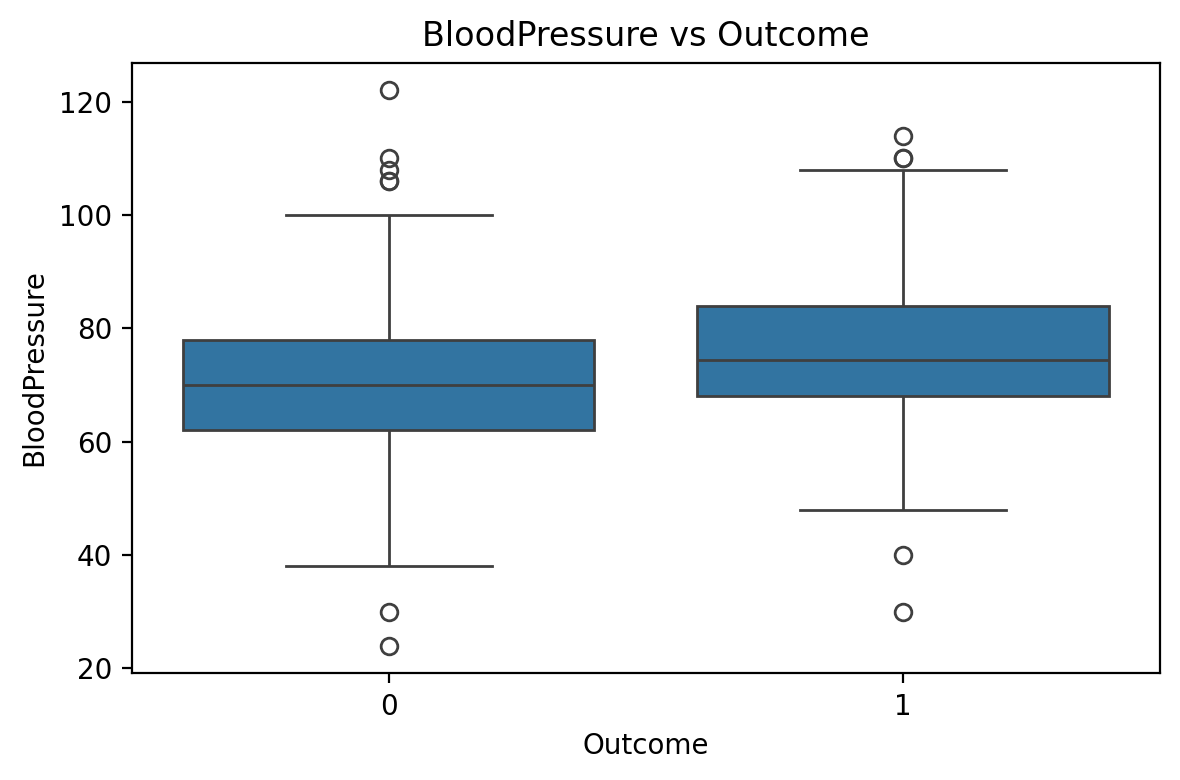

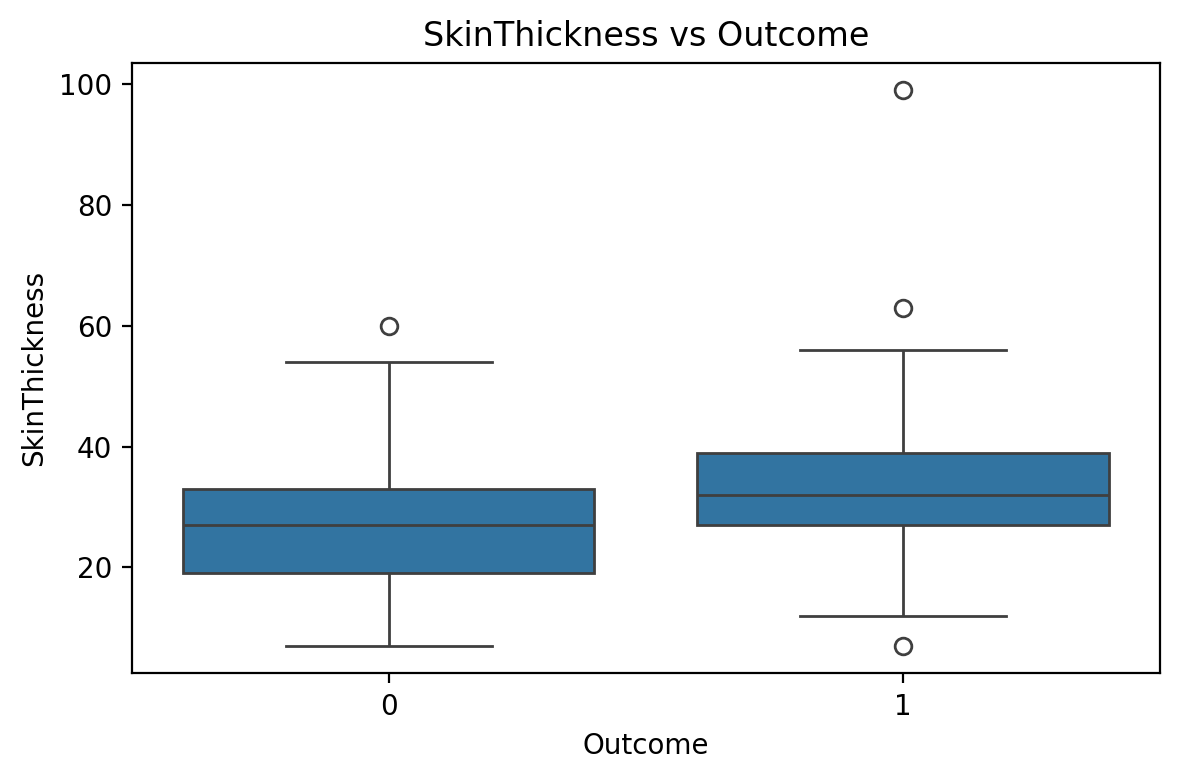

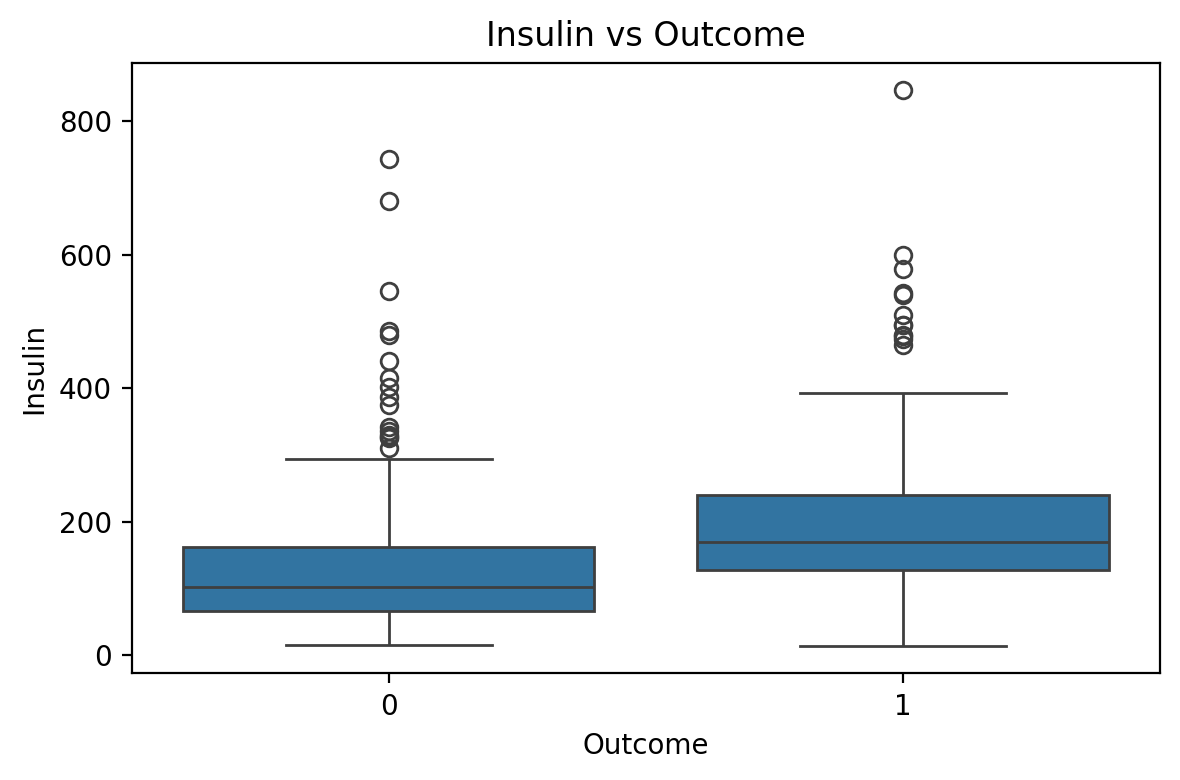

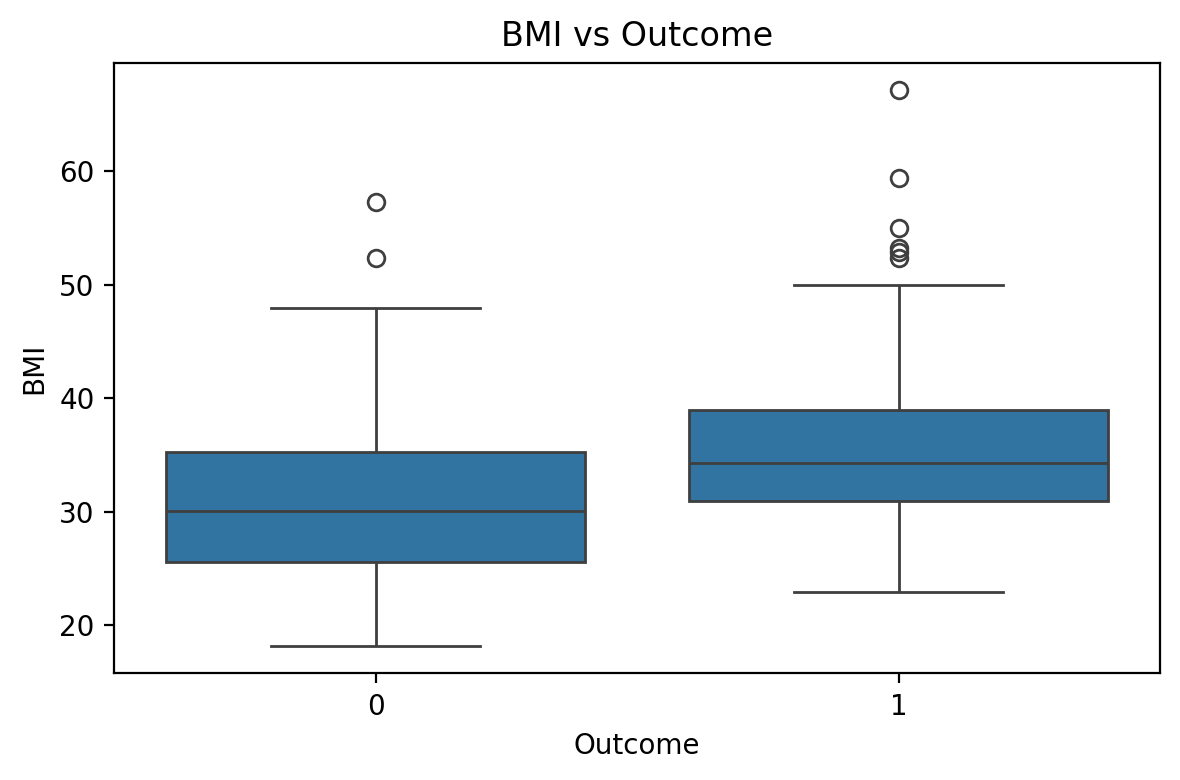

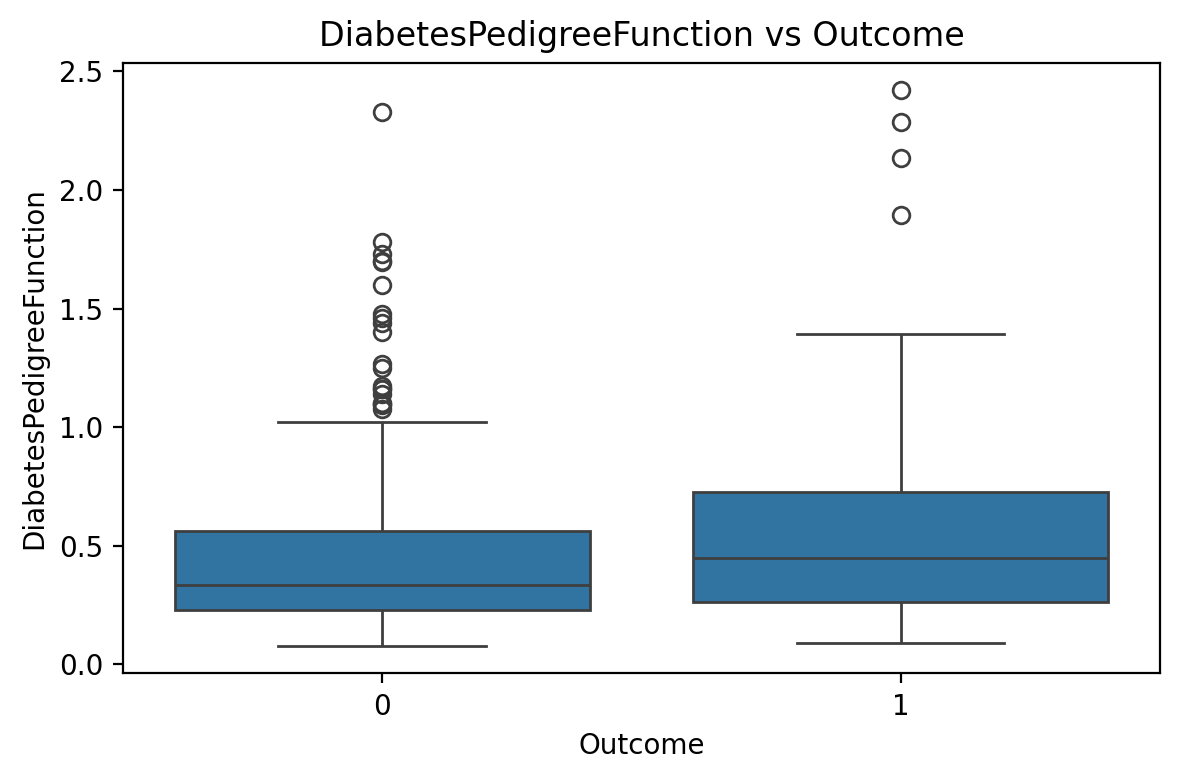

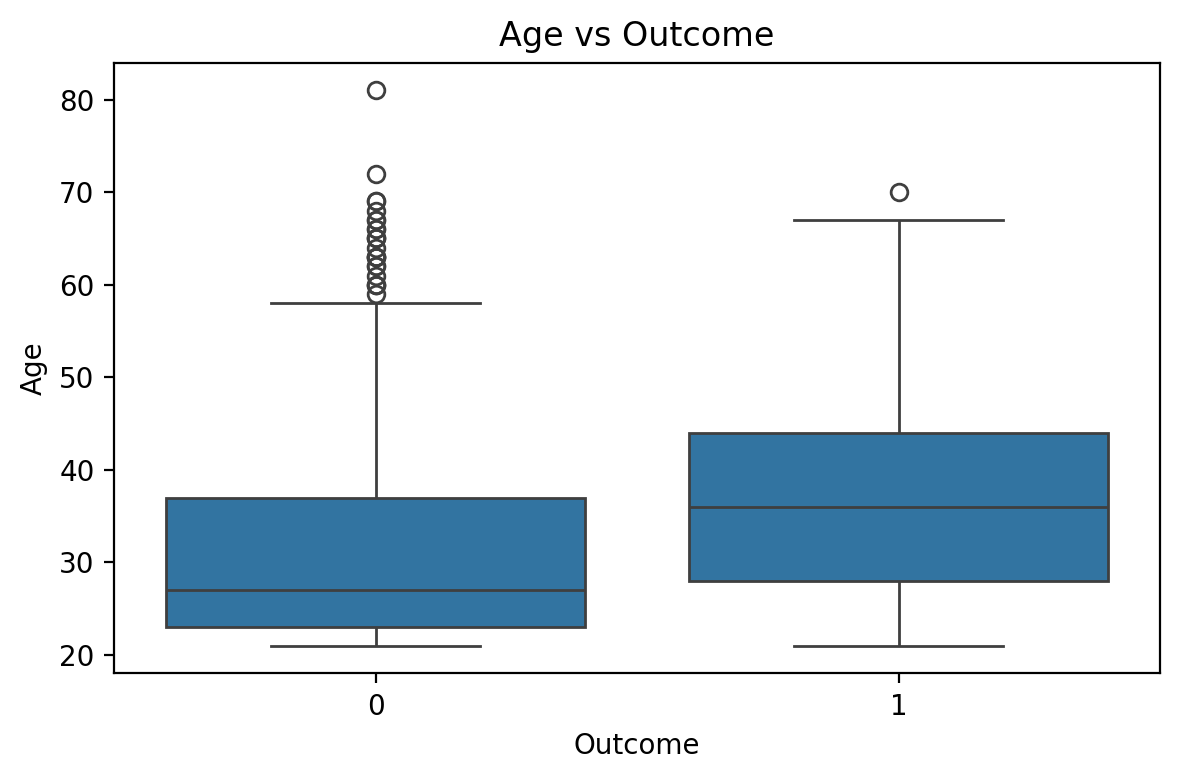

In [7]:
features= [c for c in df.columns if c != TARGET]

num_cols=df[features].select_dtypes(include=np.number)
num_cols
num_features = df.select_dtypes(include=np.number).columns.tolist()

for col in num_features:
    if col != "Outcome":
        plt.figure(figsize=(6, 4), dpi=200)
        sns.boxplot(data=df, x="Outcome", y=col)
        plt.title(f"{col} vs Outcome")
        plt.tight_layout()
        plt.show()

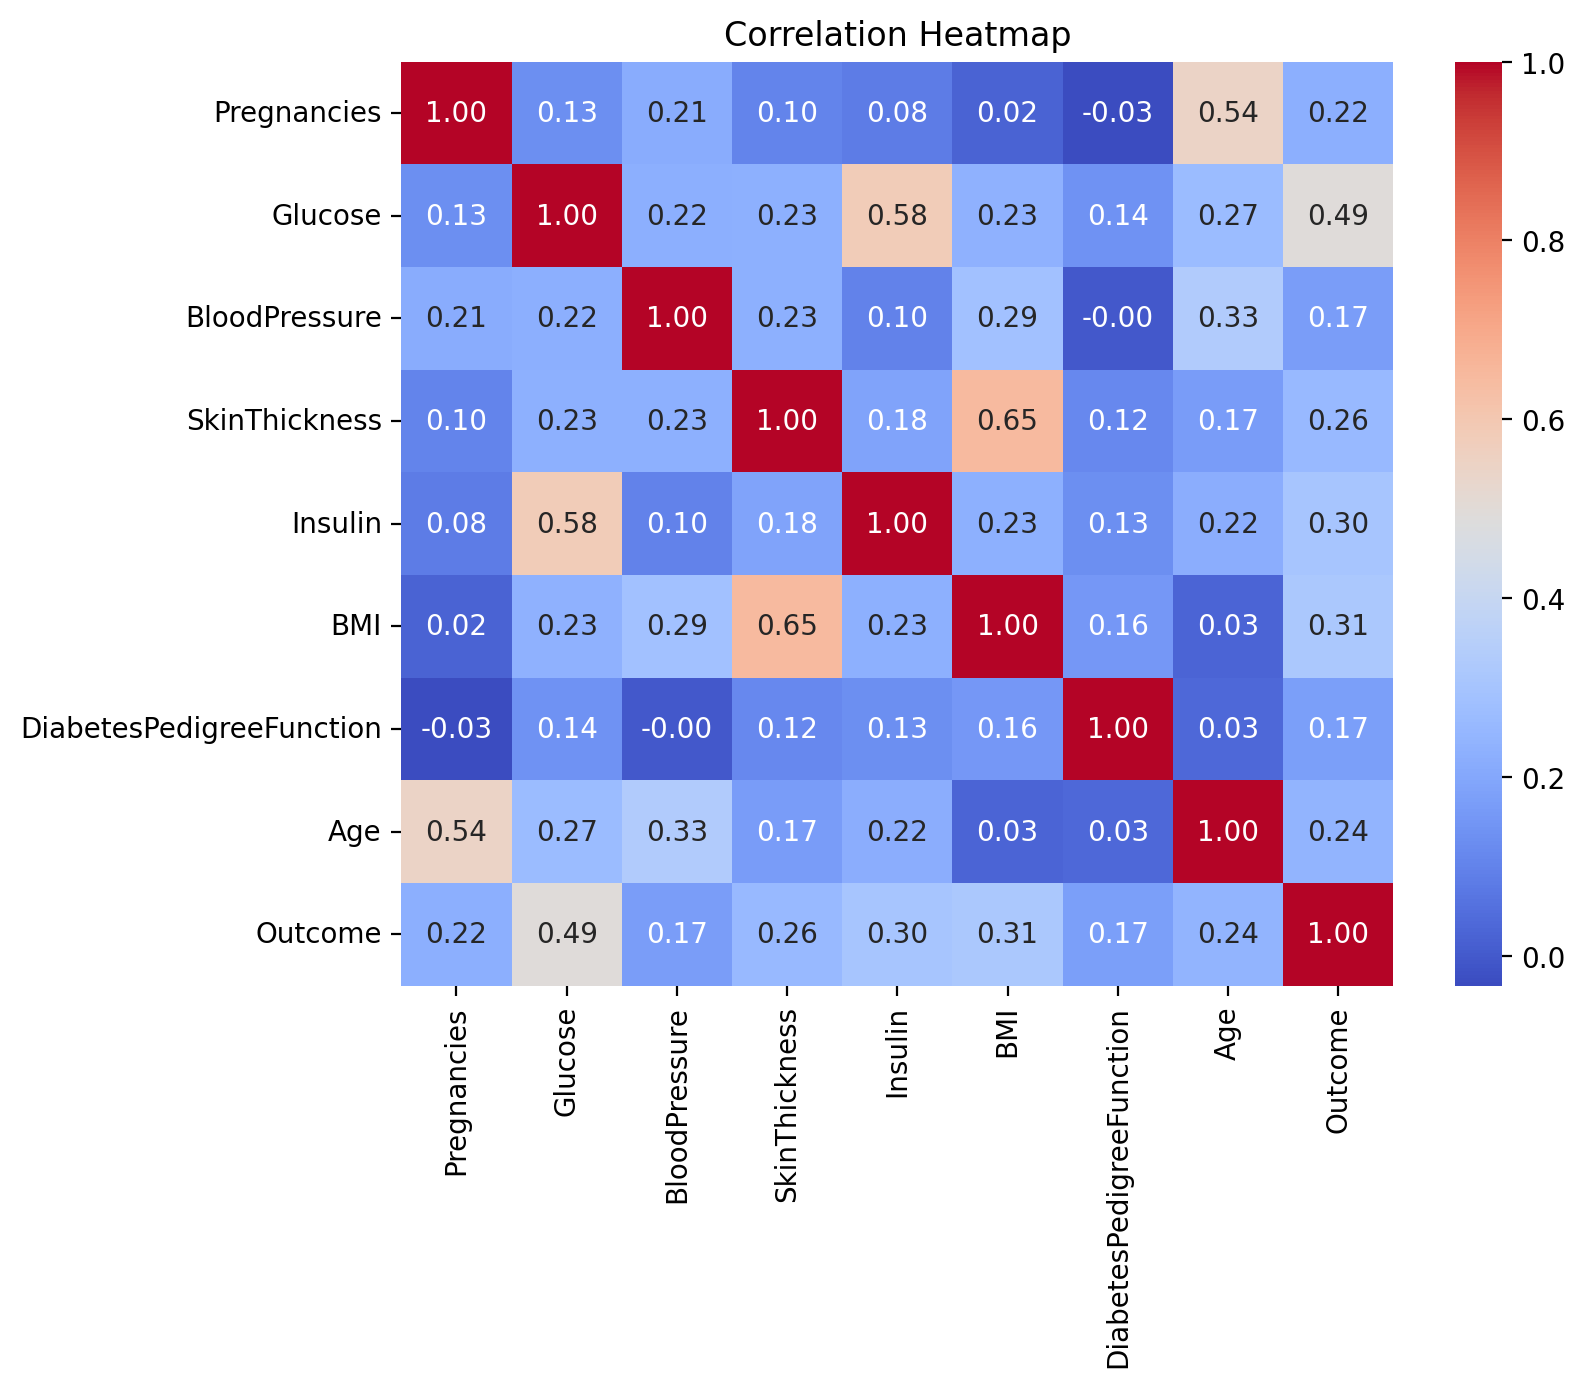

In [8]:
corr_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(8, 6), dpi=200)
sns.heatmap(corr_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

## 5. Train/test split and preprocessing

The test set is held out before any model fitting. Imputation, encoding, and scaling are fitted within each pipeline using training data only. SMOTE is also applied only inside the training pipeline, never to the test set.

For comparison, the same split is used for all six models.


In [9]:
# Separate features and target
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train = X_train.copy()
X_test = X_test.copy()

# Outlier capping (IQR) - caps are calculated from the TRAINING data only,
# then the same caps are applied to the test data (avoids data leakage)
cap_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI", "DiabetesPedigreeFunction"]
outlier_summary = []
for col in cap_cols:
    q1 = X_train[col].quantile(0.25)
    q3 = X_train[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((X_train[col] < lower) | (X_train[col] > upper)).sum()
    X_train[col] = X_train[col].clip(lower=lower, upper=upper)
    X_test[col] = X_test[col].clip(lower=lower, upper=upper)
    outlier_summary.append({"Feature": col, "Lower cap": lower, "Upper cap": upper, "Values capped (train)": int(count)})

print("Outlier capping summary:")
display(pd.DataFrame(outlier_summary).round(2))




Outlier capping summary:


,Feature,Lower cap,Upper cap,Values capped (train)
0,Glucose,36.38,203.38,0
1,BloodPressure,40.00,104.00,13
2,SkinThickness,-1.50,58.50,2
3,Insulin,-85.25,344.75,17
4,BMI,14.10,50.10,6
5,DiabetesPedigreeFunction,-0.35,1.23,19


In [10]:
# Identify numerical and categorical columns
num_cols = X.select_dtypes(include=np.number).columns
cat_cols = X.select_dtypes(exclude=np.number).columns

# Preprocessing
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
])

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Diabetic cases in test set:", y_test.sum())

Training shape: (614, 8)
Testing shape: (154, 8)
Diabetic cases in test set: 54


## 6. Baseline models — without SMOTE

All three models use preprocessing pipelines. The evaluation includes accuracy, precision, recall, F1, ROC-AUC, and a confusion matrix.



Logistic Regression
Accuracy : 0.6948
Precision: 0.5778
Recall   : 0.4815
F1-score : 0.5253
ROC-AUC  : 0.8139


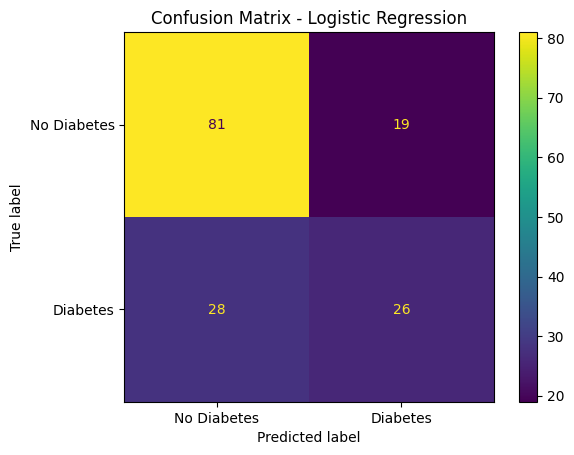


Decision Tree
Accuracy : 0.6883
Precision: 0.56
Recall   : 0.5185
F1-score : 0.5385
ROC-AUC  : 0.6493


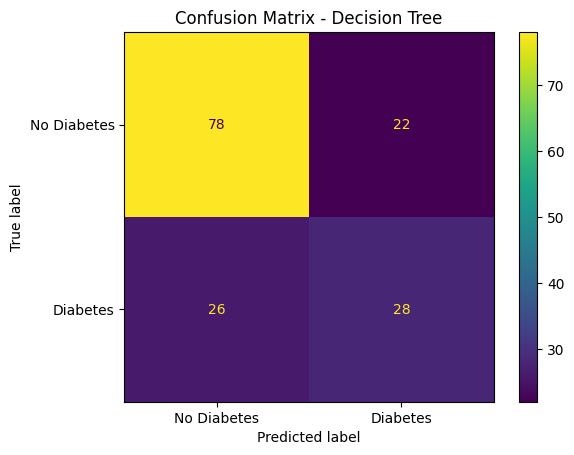


Random Forest
Accuracy : 0.7468
Precision: 0.6744
Recall   : 0.537
F1-score : 0.5979
ROC-AUC  : 0.8067


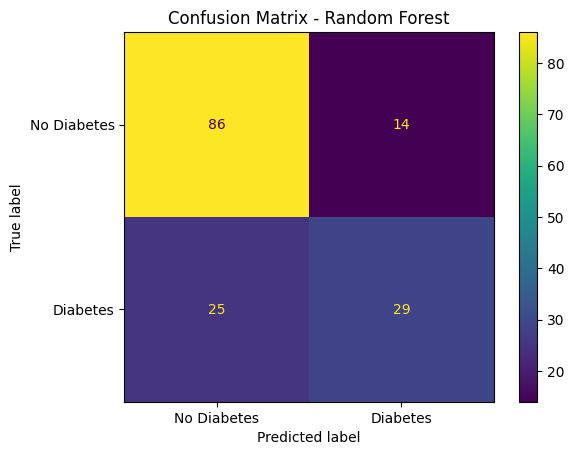

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.6948,0.5778,0.4815,0.5253,0.8139
Decision Tree,0.6883,0.5600,0.5185,0.5385,0.6493
Random Forest,0.7468,0.6744,0.5370,0.5979,0.8067


In [11]:
# Baseline models
baseline_models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "Decision Tree": Pipeline([
        ("preprocessor", preprocessor),
        ("model", DecisionTreeClassifier(random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(n_estimators=200, max_depth=5, min_samples_leaf=5, random_state=42))
    ])
}

baseline_results = []

for name, model in baseline_models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    print(f"\n{name}")
    print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
    print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
    print("Recall   :", round(recall_score(y_test, y_pred, zero_division=0), 4))
    print("F1-score :", round(f1_score(y_test, y_pred, zero_division=0), 4))
    print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 4))

    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, display_labels=["No Diabetes", "Diabetes"], cmap="viridis"
    )
    plt.title(f"Confusion Matrix - {name}")
    plt.show()

    baseline_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

baseline_metrics = pd.DataFrame(baseline_results).set_index("Model")
display(baseline_metrics.round(4))


## 7. SMOTE models

These are separate pipelines with distinct names so they can be compared with the baseline models in the research paper. SMOTE is executed after preprocessing and only during `fit` on the training data.



Logistic Regression - SMOTE
Accuracy : 0.7208
Precision: 0.5902
Recall   : 0.6667
F1-score : 0.6261
ROC-AUC  : 0.8083


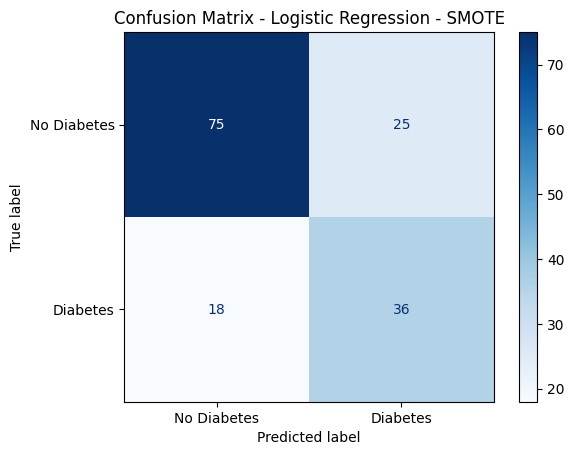


Decision Tree - SMOTE
Accuracy : 0.6753
Precision: 0.5312
Recall   : 0.6296
F1-score : 0.5763
ROC-AUC  : 0.6648


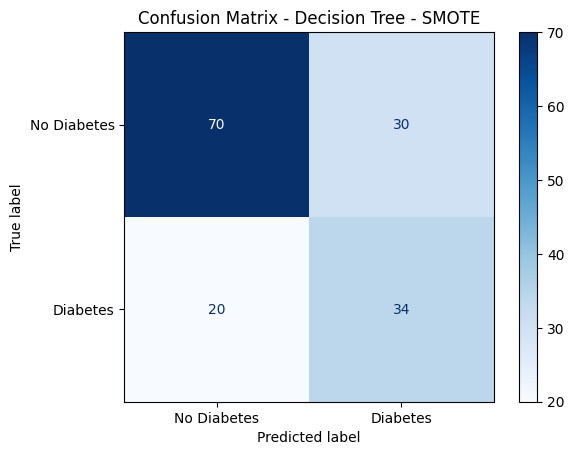


Random Forest - SMOTE
Accuracy : 0.7208
Precision: 0.5753
Recall   : 0.7778
F1-score : 0.6614
ROC-AUC  : 0.8167


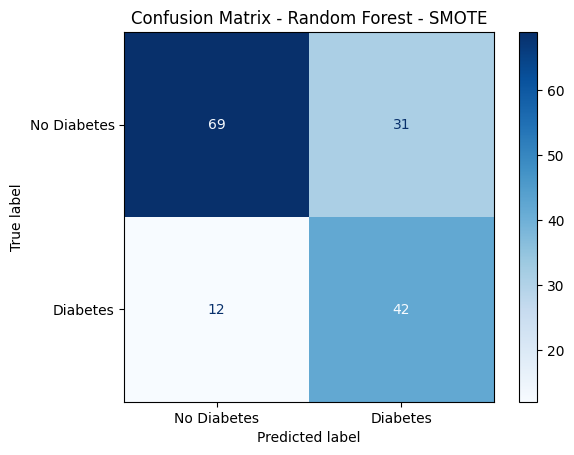

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression - SMOTE,0.7208,0.5902,0.6667,0.6261,0.8083
Decision Tree - SMOTE,0.6753,0.5312,0.6296,0.5763,0.6648
Random Forest - SMOTE,0.7208,0.5753,0.7778,0.6614,0.8167


In [12]:
# Models with SMOTE
smote_models = {
    "Logistic Regression - SMOTE": ImbPipeline([
        ("preprocessor", preprocessor),
        ("smote", SMOTE(random_state=42)),
        ("model", LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "Decision Tree - SMOTE": ImbPipeline([
        ("preprocessor", preprocessor),
        ("smote", SMOTE(random_state=42)),
        ("model", DecisionTreeClassifier(random_state=42))
    ]),
    "Random Forest - SMOTE": ImbPipeline([
        ("preprocessor", preprocessor),
        ("smote", SMOTE(random_state=42)),
        ("model", RandomForestClassifier(n_estimators=200, max_depth=5, 
                                         min_samples_leaf=5, random_state=42))
    ])
}

smote_results = []

for name, model in smote_models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    print(f"\n{name}")
    print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
    print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
    print("Recall   :", round(recall_score(y_test, y_pred, zero_division=0), 4))
    print("F1-score :", round(f1_score(y_test, y_pred, zero_division=0), 4))
    print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 4))

    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, display_labels=["No Diabetes", "Diabetes"], cmap="Blues"
    )
    plt.title(f"Confusion Matrix - {name}")
    plt.show()

    smote_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

smote_metrics = pd.DataFrame(smote_results).set_index("Model")
display(smote_metrics.round(4))


## 8. Research comparison table (holdout test set)

The combined table keeps all six experiments separate. Do not select a model based only on accuracy, because the outcome classes are imbalanced. Note that the test set has only ~54 diabetic cases, so these single-split numbers are noisy — section 9 gives the more reliable estimate.


In [ ]:
comparison = pd.concat([baseline_metrics, smote_metrics])
display(comparison.round(4))

# Bar chart: each metric before vs after SMOTE
plot_df = comparison.copy()
plot_df["Algorithm"] = [m.replace(" - SMOTE", "") for m in plot_df.index]
plot_df["Setting"] = ["With SMOTE" if "SMOTE" in m else "Without SMOTE" for m in plot_df.index]

metrics = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
fig, axes = plt.subplots(1, len(metrics), figsize=(20, 4), dpi=150)
for ax, metric in zip(axes, metrics):
    sns.barplot(data=plot_df, x="Algorithm", y=metric, hue="Setting", ax=ax)
    ax.set_title(metric)
    ax.set_ylim(0, 1)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
    if ax != axes[-1]:
        ax.get_legend().remove()
plt.tight_layout()
plt.show()


## 9. Repeated stratified cross-validation (main results)

A single 80/20 split depends heavily on which rows land in the test set. Here every model is evaluated with **5-fold stratified cross-validation repeated 10 times** (50 runs) and we report mean ± standard deviation.

All preprocessing (imputation, scaling) and SMOTE run inside the pipeline, so they are fitted on the training folds only. For simplicity, outlier capping is not used in this section.


In [13]:
X_cv = df.drop("Outcome", axis=1)
y_cv = df["Outcome"]

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1-score": "f1",
    "ROC-AUC": "roc_auc"
}

all_models = {**baseline_models, **smote_models}
cv_results = []
cv_raw = {}

for name, model in all_models.items():
    scores = cross_validate(model, X_cv, y_cv, cv=cv, scoring=scoring, n_jobs=-1)
    row = {"Model": name}
    for metric in scoring:
        values = scores["test_" + metric]
        row[metric] = f"{values.mean():.3f} ± {values.std():.3f}"
    cv_results.append(row)
    cv_raw[name] = scores
    print(name, "done")

cv_table = pd.DataFrame(cv_results).set_index("Model")
display(cv_table)


Logistic Regression done
Decision Tree done
Random Forest done
Logistic Regression - SMOTE done
Decision Tree - SMOTE done
Random Forest - SMOTE done


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.767 ± 0.029,0.713 ± 0.058,0.558 ± 0.067,0.624 ± 0.054,0.835 ± 0.027
Decision Tree,0.700 ± 0.038,0.571 ± 0.058,0.582 ± 0.072,0.574 ± 0.055,0.673 ± 0.041
Random Forest,0.763 ± 0.026,0.709 ± 0.056,0.548 ± 0.056,0.616 ± 0.046,0.840 ± 0.026
Logistic Regression - SMOTE,0.755 ± 0.035,0.633 ± 0.049,0.716 ± 0.063,0.670 ± 0.047,0.835 ± 0.028
Decision Tree - SMOTE,0.695 ± 0.032,0.559 ± 0.045,0.604 ± 0.058,0.579 ± 0.044,0.674 ± 0.035
Random Forest - SMOTE,0.757 ± 0.031,0.622 ± 0.040,0.779 ± 0.049,0.691 ± 0.037,0.835 ± 0.029


Positive = SMOTE improved the metric, negative = SMOTE lowered it


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Algorithm,,,,,
Logistic Regression,-0.012,-0.081,0.157,0.046,0.000
Decision Tree,-0.005,-0.012,0.022,0.005,0.001
Random Forest,-0.006,-0.086,0.231,0.075,-0.004


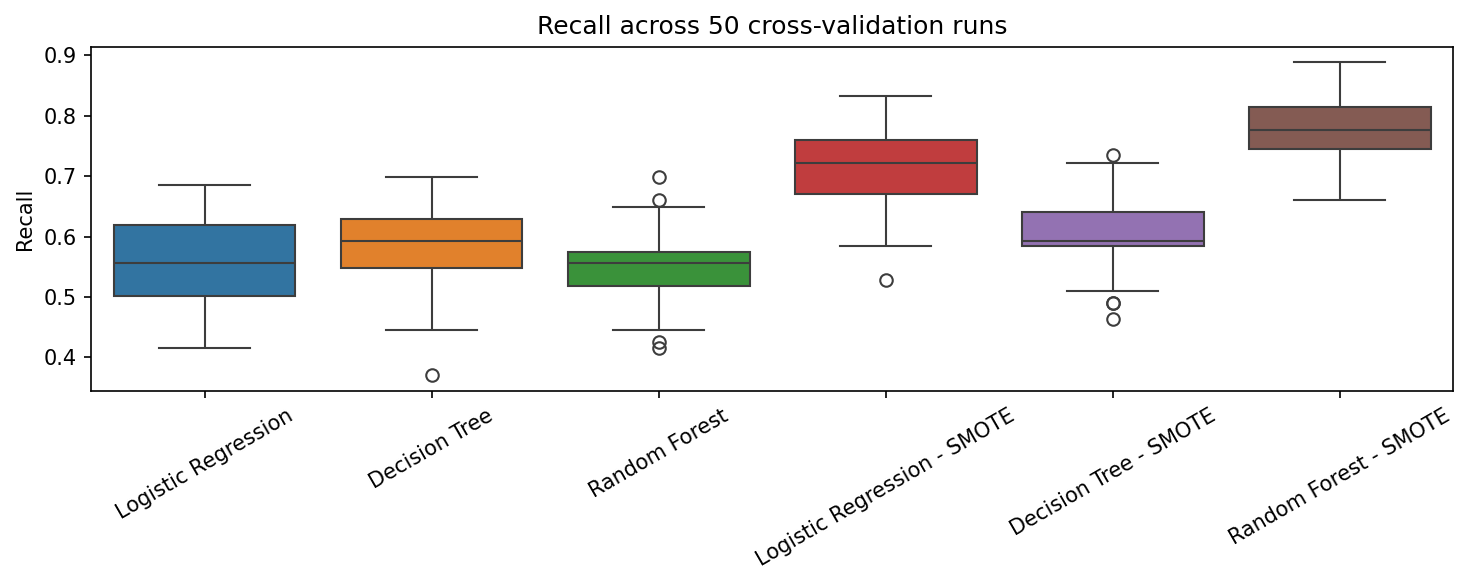

In [14]:
# Change caused by SMOTE (SMOTE mean - baseline mean)
change_rows = []
for name in baseline_models:
    row = {"Algorithm": name}
    for metric in scoring:
        before = cv_raw[name]["test_" + metric].mean()
        after = cv_raw[name + " - SMOTE"]["test_" + metric].mean()
        row[metric] = round(after - before, 3)
    change_rows.append(row)

change_table = pd.DataFrame(change_rows).set_index("Algorithm")
print("Positive = SMOTE improved the metric, negative = SMOTE lowered it")
display(change_table)

# Recall distribution across the 50 runs
recall_df = pd.DataFrame({name: cv_raw[name]["test_Recall"] for name in all_models})
plt.figure(figsize=(10, 4), dpi=150)
sns.boxplot(data=recall_df)
plt.title("Recall across 50 cross-validation runs")
plt.ylabel("Recall")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


## Notes for reporting

- Report the split ratio, the CV setup (5-fold × 10 repeats) and the random seed so the experiment is reproducible.
- SMOTE is applied only to training data/folds; the test data always keeps the original class distribution.
- Use the section 9 cross-validation table as the main result; the section 8 holdout table is a single example split.
- The dataset is only mildly imbalanced (~35% diabetic), so the effect of SMOTE is moderate. Mention this as a limitation.
- This is a predictive modelling exercise, not a diagnostic tool.
